# Apriori vs FP-Growth and rule thresholds

This notebook uses the week 4 app data. It compares two frequent-itemset algorithms and tests rule thresholds. All analysis code is here.


## Data

`transactions.js` stores one basket per retained invoice. Item indices identify StockCodes, and Descriptions are labels. We remove any duplicate item inside a basket.


In [1]:
from pathlib import Path
import json
import math
import platform

paths = [
    Path('transactions.js'),
    Path('week4/transactions.js'),
    Path('../week4/transactions.js'),
    Path('llm-4-res-sys/week4/transactions.js'),
]
data_path = next((path for path in paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Run this notebook from week4, the project, or the workspace folder.')

source = data_path.read_text(encoding='utf-8')
payload = source.split('window.HW4 = ', 1)[1].strip()
assert payload.endswith(';')
data = json.loads(payload[:-1])
baskets = [tuple(sorted(set(row))) for row in data['baskets']]
assert len(baskets) == data['N_BASKETS']
assert len(data['stocks']) == len(data['descriptions']) == data['N_ITEMS']

min_support = 0.01
min_count = math.ceil(len(baskets) * min_support)
print(f'{len(baskets):,} baskets; {len(data["stocks"]):,} items')
print(f'Minimum support: {min_support:.0%} = {min_count} baskets')
print(f'Python {platform.python_version()} on {platform.system()}')


17,080 baskets; 3,653 items
Minimum support: 1% = 171 baskets
Python 3.13.7 on Darwin


## Frequent itemsets

Apriori grows item groups from smaller groups. FP-Growth compresses shared basket prefixes into a tree. The next cell contains both implementations.


In [2]:
"""Frequent-itemset algorithms used by the week 4 analysis notebook."""

from collections import Counter, defaultdict


def apriori(baskets, min_count):
    postings = defaultdict(set)
    for basket_id, basket in enumerate(baskets):
        for item in basket:
            postings[item].add(basket_id)
    level = {(item,): tids for item, tids in postings.items() if len(tids) >= min_count}
    counts = {}
    while level:
        counts.update({items: len(tids) for items, tids in level.items()})
        keys = sorted(level)
        known = set(keys)
        next_level = {}
        for pos, left in enumerate(keys):
            for right in keys[pos + 1:]:
                if left[:-1] != right[:-1]:
                    break
                candidate = left + (right[-1],)
                if any(candidate[:i] + candidate[i + 1:] not in known for i in range(len(candidate))):
                    continue
                tids = level[left] & level[right]
                if len(tids) >= min_count:
                    next_level[candidate] = tids
        level = next_level
    return counts


class FPNode:
    __slots__ = ('item', 'count', 'parent', 'children')

    def __init__(self, item, count, parent):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}


def build_fp_tree(paths, min_count):
    counts = Counter()
    for path, weight in paths:
        for item in path:
            counts[item] += weight
    frequent = {item for item, count in counts.items() if count >= min_count}
    if not frequent:
        return None, None, None
    order = {item: rank for rank, item in enumerate(sorted(frequent, key=lambda item: (-counts[item], item)))}
    root = FPNode(None, 0, None)
    header = defaultdict(list)
    for path, weight in paths:
        node = root
        for item in sorted((item for item in path if item in frequent), key=order.__getitem__):
            child = node.children.get(item)
            if child is None:
                child = FPNode(item, 0, node)
                node.children[item] = child
                header[item].append(child)
            child.count += weight
            node = child
    return root, header, counts


def fp_growth(baskets, min_count):
    found = {}

    def mine(paths, suffix):
        root, header, counts = build_fp_tree(paths, min_count)
        if root is None:
            return
        for item in sorted(header, key=lambda item: (counts[item], item)):
            pattern = tuple(sorted((*suffix, item)))
            found[pattern] = counts[item]
            conditional = []
            for node in header[item]:
                prefix = []
                parent = node.parent
                while parent.item is not None:
                    prefix.append(parent.item)
                    parent = parent.parent
                if prefix:
                    conditional.append((tuple(reversed(prefix)), node.count))
            if conditional:
                mine(conditional, (*suffix, item))

    mine([(basket, 1) for basket in baskets], ())
    return found




## Time and memory

Both methods use 1% support and the same baskets. Time is the median of five runs. Memory is peak traced Python allocation in a separate run, excluding data loading.


In [3]:
"""Measure the two frequent-itemset methods on the same loaded baskets."""

import gc
import statistics
import time
import tracemalloc



def compare_methods(baskets, min_count, example_item, repeats=5):
    """Return comparable timing and traced-memory results.

    Data loading is excluded. Timing and memory are measured in separate runs.
    """
    methods = [("Apriori", apriori), ("FP-Growth", fp_growth)]
    reference = apriori(baskets, min_count)
    assert fp_growth(baskets, min_count) == reference
    itemset_count = len(reference)
    example_count = reference[(example_item,)]

    times = {name: [] for name, _ in methods}
    for repeat in range(repeats):
        order = methods if repeat % 2 == 0 else methods[::-1]
        for name, method in order:
            gc.collect()
            start = time.perf_counter()
            found = method(baskets, min_count)
            times[name].append(time.perf_counter() - start)
            assert found == reference
            del found
    del reference

    peak_mib = {}
    for name, method in methods:
        gc.collect()
        tracemalloc.start()
        found = method(baskets, min_count)
        peak_mib[name] = tracemalloc.get_traced_memory()[1] / (1024 ** 2)
        tracemalloc.stop()
        assert len(found) == itemset_count
        del found

    comparison = [
        {
            "algorithm": name,
            "itemsets": itemset_count,
            "median_seconds": statistics.median(times[name]),
            "peak_mib": peak_mib[name],
        }
        for name, _ in methods
    ]
    return comparison, itemset_count, example_count


In [4]:
item_index = data['stocks'].index('85123A')
comparison, itemset_count, example_count = compare_methods(
    baskets, min_count, item_index, repeats=5
)
assert example_count == 1959
print(f'Both methods found the same {itemset_count:,} frequent itemsets.')
print(f'Example: 85123A appears in {example_count:,} baskets.')


Both methods found the same 1,219 frequent itemsets.
Example: 85123A appears in 1,959 baskets.


In [5]:
print(f'{"Algorithm":<12} {"Itemsets":>8} {"Median time (s)":>17} {"Peak traced (MiB)":>18}')
for row in comparison:
    print(f'{row["algorithm"]:<12} {row["itemsets"]:>8,} {row["median_seconds"]:>17.3f} {row["peak_mib"]:>18.1f}')

faster = min(comparison, key=lambda row: row['median_seconds'])['algorithm']
leaner = min(comparison, key=lambda row: row['peak_mib'])['algorithm']
time_gap = abs(comparison[0]['median_seconds'] - comparison[1]['median_seconds']) / max(
    row['median_seconds'] for row in comparison)
print(f'\nConclusion: Both methods found the same {itemset_count:,} frequent itemsets.')
if time_gap < 0.05:
    print('Their median times were close in this run (within 5%).')
else:
    print(f'{faster} had the lower median time in this run.')
print(f'{leaner} used less traced memory in this run.')
print('These results describe the Python versions here; another run or setup may differ.')


Algorithm    Itemsets   Median time (s)  Peak traced (MiB)
Apriori         1,219             1.899               28.6
FP-Growth       1,219             1.103               59.5

Conclusion: Both methods found the same 1,219 frequent itemsets.
FP-Growth had the lower median time in this run.
Apriori used less traced memory in this run.
These results describe the Python versions here; another run or setup may differ.


## Choosing rule thresholds

Support is the share of baskets with all items in a rule. Confidence is the share of baskets with the left side that also contain the right side. Lift above 1 means the sides occur together more often than independence predicts. We mine at 0.5% support, then vary one threshold at a time.


In [6]:
from itertools import combinations


def make_rules(itemset_counts, basket_count):
    """Generate both directions of every rule from frequent itemsets."""
    rules = []
    for items, joint_count in itemset_counts.items():
        if len(items) < 2:
            continue
        for size in range(1, len(items)):
            for antecedent in combinations(items, size):
                left = set(antecedent)
                consequent = tuple(item for item in items if item not in left)
                confidence = joint_count / itemset_counts[antecedent]
                lift = confidence / (itemset_counts[consequent] / basket_count)
                rules.append({
                    'antecedent': antecedent,
                    'consequent': consequent,
                    'joint_count': joint_count,
                    'support': joint_count / basket_count,
                    'confidence': confidence,
                    'lift': lift,
                })
    return rules


def compare_thresholds(itemset_counts, rules, settings, basket_count):
    """Filter the same candidate rules at several thresholds."""
    rows = []
    for min_support, min_confidence in settings:
        min_count = math.ceil(basket_count * min_support)
        passing = [rule for rule in rules
                   if rule['joint_count'] >= min_count and rule['confidence'] >= min_confidence]
        retained = [rule for rule in passing if rule['lift'] > 1]
        rows.append({
            'support': min_support,
            'confidence': min_confidence,
            'min_baskets': min_count,
            'itemsets': sum(count >= min_count for count in itemset_counts.values()),
            'rules': len(passing),
            'lift_above_one': len(retained),
            'retained_rules': retained,
        })
    return rows


In [7]:
mining_floor = 0.005  # Start low, then apply stricter filters to the same candidates.
candidate_itemsets = fp_growth(baskets, math.ceil(len(baskets) * mining_floor))
candidate_rules = make_rules(candidate_itemsets, len(baskets))
print(f'Mining floor: {mining_floor:.1%}; {len(candidate_itemsets):,} itemsets and '
      f'{len(candidate_rules):,} possible directed rules.')

support_levels = [0.005, 0.01, 0.015, 0.02, 0.025, 0.03]
confidence_levels = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
settings = [(support, 0.30) for support in support_levels]
settings += [(0.02, confidence) for confidence in confidence_levels if confidence != 0.30]
threshold_rows = compare_thresholds(candidate_itemsets, candidate_rules, settings, len(baskets))

print('\nChange support; hold confidence at 30%:')
print(f'{"Support":>8} {"Min baskets":>12} {"Itemsets":>9} {"Rules":>7} {"Lift > 1":>9}')
for row in threshold_rows[:len(support_levels)]:
    print(f'{row["support"]:>8.1%} {row["min_baskets"]:>12,} {row["itemsets"]:>9,} '
          f'{row["rules"]:>7,} {row["lift_above_one"]:>9,}')

print('\nChange confidence; hold support at 2%:')
print(f'{"Confidence":>11} {"Rules":>7} {"Lift > 1":>9}')
for confidence in confidence_levels:
    row = next(row for row in threshold_rows
               if row['support'] == 0.02 and row['confidence'] == confidence)
    print(f'{row["confidence"]:>11.0%} {row["rules"]:>7,} {row["lift_above_one"]:>9,}')


Mining floor: 0.5%; 5,255 itemsets and 21,026 possible directed rules.

Change support; hold confidence at 30%:
 Support  Min baskets  Itemsets   Rules  Lift > 1
    0.5%           86     5,255  10,723    10,723
    1.0%          171     1,219     950       950
    1.5%          257       549     275       275
    2.0%          342       294      96        96
    2.5%          427       185      45        45
    3.0%          513       115      12        12

Change confidence; hold support at 2%:
 Confidence   Rules  Lift > 1
        10%     108       108
        20%     108       108
        30%      96        96
        40%      76        76
        50%      36        36
        60%      20        20


## Rule distributions

Each histogram shows all directed candidate rules mined at the 0.5% support floor. A rule and its reverse are separate. Dashed lines mark the suggested 2% support and 30% confidence cutoffs.


In [8]:
from bisect import bisect_right
from html import escape


def histogram_svg(values, edges, cutoff, title, x_label, color):
    """Draw a labeled histogram using only Python's standard library."""
    counts = [0] * (len(edges) - 1)
    for value in values:
        index = min(bisect_right(edges, value) - 1, len(counts) - 1)
        if not 0 <= index < len(counts):
            raise ValueError('A value is outside the histogram bins')
        counts[index] += 1
    assert sum(counts) == len(values)

    width, height = 860, 360
    left, right, top, bottom = 78, 28, 55, 68
    plot_width = width - left - right
    plot_height = height - top - bottom
    maximum = max(counts) * 1.08
    x_pos = lambda value: left + (value - edges[0]) / (edges[-1] - edges[0]) * plot_width
    y_pos = lambda value: top + plot_height * (1 - value / maximum)

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
        f'viewBox="0 0 {width} {height}" role="img" aria-label="{escape(title)}">',
        f'<title>{escape(title)}</title>',
        f'<desc>{len(values):,} candidate directed rules; dashed line marks the suggested cutoff.</desc>',
        f'<rect width="{width}" height="{height}" fill="white"/>',
        f'<text x="{width/2}" y="29" text-anchor="middle" font-size="20" '
        f'font-family="sans-serif" fill="#172033">{escape(title)}</text>',
    ]
    for tick in range(5):
        value = maximum * tick / 4
        y = y_pos(value)
        parts.append(f'<line x1="{left}" x2="{width-right}" y1="{y:.1f}" y2="{y:.1f}" '
                     'stroke="#dbe3ed" stroke-width="1"/>')
        parts.append(f'<text x="{left-10}" y="{y+4:.1f}" text-anchor="end" font-size="12" '
                     f'font-family="sans-serif" fill="#344054">{value:,.0f}</text>')
    for index, count in enumerate(counts):
        x0, x1 = x_pos(edges[index]), x_pos(edges[index + 1])
        bar_top = y_pos(count)
        parts.append(f'<rect x="{x0+2:.1f}" y="{bar_top:.1f}" width="{x1-x0-4:.1f}" '
                     f'height="{top+plot_height-bar_top:.1f}" fill="{color}"/>')
    for index in range(0, len(edges), max(1, (len(edges)-1)//6)):
        x = x_pos(edges[index])
        parts.append(f'<text x="{x:.1f}" y="{height-bottom+22}" text-anchor="middle" '
                     f'font-size="12" font-family="sans-serif" fill="#344054">{edges[index]:.1%}</text>')
    if (len(edges) - 1) % max(1, (len(edges)-1)//6):
        x = x_pos(edges[-1])
        parts.append(f'<text x="{x:.1f}" y="{height-bottom+22}" text-anchor="middle" '
                     f'font-size="12" font-family="sans-serif" fill="#344054">{edges[-1]:.1%}</text>')
    marker = x_pos(cutoff)
    parts.append(f'<line x1="{marker:.1f}" x2="{marker:.1f}" y1="{top}" y2="{top+plot_height}" '
                 'stroke="#c23b22" stroke-width="2" stroke-dasharray="6 4"/>')
    parts.append(f'<text x="{min(marker+8, width-145):.1f}" y="{top+15}" '
                 f'font-size="12" font-family="sans-serif" fill="#a32915">cutoff {cutoff:.0%}</text>')
    parts.append(f'<text x="{width/2}" y="{height-9}" text-anchor="middle" font-size="13" '
                 f'font-family="sans-serif" fill="#172033">{escape(x_label)}</text>')
    parts.append(f'<text transform="translate(18 {top+plot_height/2:.1f}) rotate(-90)" '
                 'text-anchor="middle" font-size="13" font-family="sans-serif" fill="#172033">Number of rules</text>')
    parts.append('</svg>')
    return ''.join(parts), counts


Each histogram contains 21,026 candidate directed rules.
20,918 have support below 2%.
10,303 have confidence below 30%.


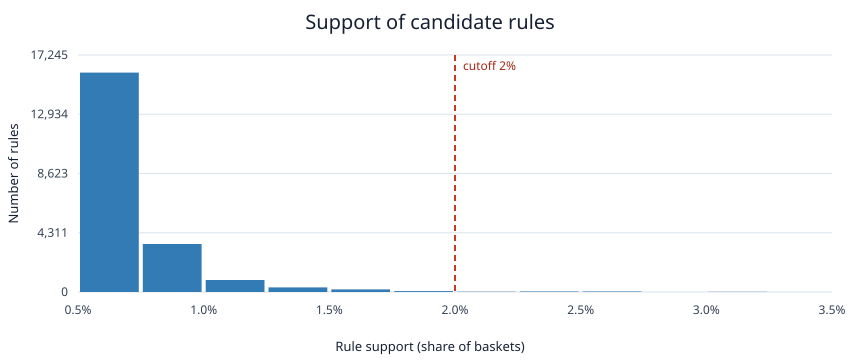

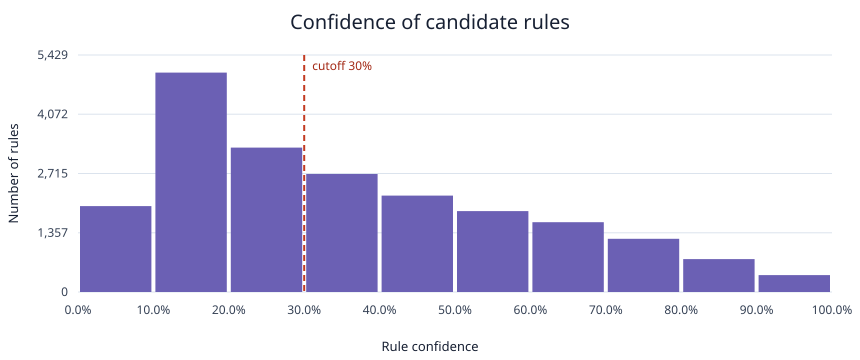

In [9]:
support_edges = [0.005 + i * 0.0025 for i in range(13)]  # 0.5% to 3.5%
confidence_edges = [i / 10 for i in range(11)]  # 0% to 100%
support_svg, support_bin_counts = histogram_svg(
    [rule['support'] for rule in candidate_rules], support_edges, 0.02,
    'Support of candidate rules', 'Rule support (share of baskets)', '#337bb5')
confidence_svg, confidence_bin_counts = histogram_svg(
    [rule['confidence'] for rule in candidate_rules], confidence_edges, 0.30,
    'Confidence of candidate rules', 'Rule confidence', '#6b60b4')
print(f'Each histogram contains {len(candidate_rules):,} candidate directed rules.')
print(f'{sum(rule["support"] < 0.02 for rule in candidate_rules):,} have support below 2%.')
print(f'{sum(rule["confidence"] < 0.30 for rule in candidate_rules):,} have confidence below 30%.')
try:
    from IPython.display import SVG, display
except ImportError:
    pass  # The saved notebook still includes both SVG charts.
else:
    display(SVG(data=support_svg))
    display(SVG(data=confidence_svg))


## Brief conclusion


In [10]:
chosen = next(row for row in threshold_rows
              if row['support'] == 0.02 and row['confidence'] == 0.30)
retained_rules = chosen['retained_rules']  # Only rules with lift > 1.
looser = next(row for row in threshold_rows
              if row['support'] == 0.01 and row['confidence'] == 0.30)
stricter = next(row for row in threshold_rows
                if row['support'] == 0.02 and row['confidence'] == 0.60)
print(f'Suggested choice: 2% support (at least {chosen["min_baskets"]} baskets) and 30% confidence.')
print(f'It leaves {chosen["rules"]} rules, compared with {looser["rules"]} at 1%/30% '
      f'and {stricter["rules"]} at 2%/60%.')
print(f'{len(retained_rules)} rules have lift > 1; the lift filter removes '
      f'{chosen["rules"] - len(retained_rules)} rules here.')
print('The histograms show why: most candidate rules have support below 2%.')


Suggested choice: 2% support (at least 342 baskets) and 30% confidence.
It leaves 96 rules, compared with 950 at 1%/30% and 20 at 2%/60%.
96 rules have lift > 1; the lift filter removes 0 rules here.
The histograms show why: most candidate rules have support below 2%.


## Check the rule in a later period

The app's `transactions.js` has no invoice dates. The [original UCI workbook](https://archive.ics.uci.edu/dataset/352/online+retail) has `InvoiceDate`, so this section rebuilds dated baskets. The workbook is analysis data only; the browser app does not use it. This section needs `pandas` and `openpyxl` in the notebook kernel.


In [11]:
from hashlib import sha256
from io import BytesIO
from urllib.request import Request, urlopen
from zipfile import ZipFile
import shutil

source_url = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
zip_path = data_path.resolve().parent / 'dev' / 'online_retail.zip'
zip_path.parent.mkdir(exist_ok=True)
if not zip_path.exists():
    request = Request(source_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(request, timeout=120) as response, zip_path.open('wb') as output:
        shutil.copyfileobj(response, output)
with ZipFile(zip_path) as archive:
    workbook_name = next(name for name in archive.namelist() if name.lower().endswith('.xlsx'))
    workbook_bytes = archive.read(workbook_name)
workbook_sha256 = sha256(workbook_bytes).hexdigest()
expected_sha256 = '43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d'
assert workbook_sha256 == expected_sha256, 'Original workbook checksum does not match the README'
print(f'Original workbook verified: {workbook_name}, SHA-256 {workbook_sha256}')


Original workbook verified: Online Retail.xlsx, SHA-256 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d


In [12]:
import pandas as pd
import openpyxl
from collections import Counter

raw = pd.read_excel(BytesIO(workbook_bytes), engine='openpyxl',
                    dtype={'InvoiceNo': 'string', 'StockCode': 'string'})
assert len(raw) == 541_909
invoice = raw['InvoiceNo'].fillna('').str.strip()
stock = raw['StockCode'].fillna('').str.strip().str.upper()
description = raw['Description'].fillna('').astype('string').str.strip()
app_stocks = set(data['stocks'])
keep = (invoice.ne('') & ~invoice.str.upper().str.startswith(('C', 'A'))
        & raw['Quantity'].gt(0) & raw['UnitPrice'].gt(0)
        & description.ne('') & raw['CustomerID'].notna()
        & stock.isin(app_stocks))
clean = pd.DataFrame({
    'InvoiceNo': invoice[keep],
    'StockCode': stock[keep],
    'InvoiceDate': pd.to_datetime(raw.loc[keep, 'InvoiceDate']),
})
assert clean['InvoiceDate'].notna().all()

invoice_rows = clean.groupby('InvoiceNo', sort=False).agg(
    items=('StockCode', lambda values: frozenset(values)),
    date=('InvoiceDate', 'min'),
    last_date=('InvoiceDate', 'max'),
    dates_per_invoice=('InvoiceDate', 'nunique'),
    source_rows=('StockCode', 'size'),
)
invoice_rows = invoice_rows[invoice_rows['items'].map(len) >= 2]
ambiguous_dates = invoice_rows[invoice_rows['dates_per_invoice'] > 1]
print(f'Invoices with more than one timestamp: {len(ambiguous_dates):,}')
if len(ambiguous_dates):
    print('Maximum date span within one invoice:', (ambiguous_dates['last_date'] - ambiguous_dates['date']).max())
    assert (ambiguous_dates['date'].dt.to_period('M') == ambiguous_dates['last_date'].dt.to_period('M')).all()
dated_baskets = [(invoice_no, row['date'], row['items'])
                 for invoice_no, row in invoice_rows.iterrows()]

app_basket_counts = Counter(tuple(sorted(data['stocks'][i] for i in row))
                            for row in data['baskets'])
rebuilt_basket_counts = Counter(tuple(sorted(items)) for _, _, items in dated_baskets)
matched = app_basket_counts == rebuilt_basket_counts
print(f'pandas {pd.__version__}; openpyxl {openpyxl.__version__}')
print(f'Raw rows: {len(raw):,}; rebuilt dated baskets: {len(dated_baskets):,}')
retained_lines = clean[clean['InvoiceNo'].isin(invoice_rows.index)]
unique_pairs = retained_lines.drop_duplicates(['InvoiceNo', 'StockCode'])
print(f'Product lines in rebuilt baskets: {len(retained_lines):,}')
print(f'Unique invoice-item pairs: {len(unique_pairs):,} '
      f'({len(retained_lines) - len(unique_pairs):,} repeated lines collapsed)')
assert len(unique_pairs) == 384_911
assert len(dated_baskets) == len(baskets)
print(f'Exact match to app basket multiset: {matched}')
if not matched:
    print('App-only baskets:', sum((app_basket_counts - rebuilt_basket_counts).values()))
    print('Rebuilt-only baskets:', sum((rebuilt_basket_counts - app_basket_counts).values()))
assert matched, 'Resolve cleaning differences before the time split'
print(f'Date range: {min(date for _, date, _ in dated_baskets):%Y-%m-%d} to '
      f'{max(date for _, date, _ in dated_baskets):%Y-%m-%d}')


Invoices with more than one timestamp: 30
Maximum date span within one invoice: 0 days 00:01:00
pandas 3.0.3; openpyxl 3.1.5
Raw rows: 541,909; rebuilt dated baskets: 17,080
Product lines in rebuilt baskets: 394,916
Unique invoice-item pairs: 384,911 (10,005 repeated lines collapsed)
Exact match to app basket multiset: True
Date range: 2010-12-01 to 2011-12-09


### Historical time split

Use full months only: January–August 2011 is the earlier period, and September–November 2011 is the later period. December 2010 and the incomplete December 2011 are omitted. Keep the previously chosen rule fixed: GREEN REGENCY TEACUP AND SAUCER [22697] → ROSES REGENCY TEACUP AND SAUCER [22699]. The rule was chosen using all baskets, so this is a retrospective stability check, not an independent test of rule discovery.


In [13]:
from statistics import NormalDist


def wilson_interval(successes, trials):
    """A 95% interval for a proportion; useful when periods have different sizes."""
    if trials == 0:
        return (float('nan'), float('nan'))
    z = NormalDist().inv_cdf(0.975)
    p = successes / trials
    scale = 1 + z * z / trials
    center = (p + z * z / (2 * trials)) / scale
    radius = z * math.sqrt(p * (1 - p) / trials + z * z / (4 * trials * trials)) / scale
    return (center - radius, center + radius)


def rule_metrics(period_baskets, left, right):
    n = len(period_baskets)
    count_a = sum(left in basket for basket in period_baskets)
    count_b = sum(right in basket for basket in period_baskets)
    both = sum(left in basket and right in basket for basket in period_baskets)
    support = both / n if n else float('nan')
    confidence = both / count_a if count_a else float('nan')
    lift = confidence / (count_b / n) if n and count_b else float('nan')
    return {'n': n, 'a': count_a, 'b': count_b, 'both': both,
            'support': support, 'confidence': confidence, 'lift': lift,
            'confidence_ci': wilson_interval(both, count_a)}

left_stock, right_stock = '22697', '22699'
early_start, split_date, late_end = (pd.Timestamp(value) for value in
                                      ('2011-01-01', '2011-09-01', '2011-12-01'))
early_baskets = [items for _, date, items in dated_baskets if early_start <= date < split_date]
later_baskets = [items for _, date, items in dated_baskets if split_date <= date < late_end]
early = rule_metrics(early_baskets, left_stock, right_stock)
later = rule_metrics(later_baskets, left_stock, right_stock)
full_period = rule_metrics([items for _, _, items in dated_baskets], left_stock, right_stock)
assert (full_period['a'], full_period['b'], full_period['both']) == (691, 780, 541)
print(f'Full app period: A={full_period["a"]}, B={full_period["b"]}, both={full_period["both"]}')
print(f'Invoices outside the two full-month periods: {full_period["n"] - early["n"] - later["n"]:,}')

print('Period       Baskets  A count  B count  Both  Support  Confidence  Lift  95% CI for confidence')
for label, row in [('Jan-Aug 2011', early), ('Sep-Nov 2011', later)]:
    lo, hi = row['confidence_ci']
    print(f'{label:<12} {row["n"]:>7,} {row["a"]:>8,} {row["b"]:>8,} {row["both"]:>5,} '
          f'{row["support"]:>7.2%} {row["confidence"]:>10.2%} {row["lift"]:>5.2f} '
          f'[{lo:.2%}, {hi:.2%}]')

print('\nMonthly check (full months only):')
print('Month    Baskets  A count  Both  Support  Confidence   Lift')
monthly_results = []
for month in pd.period_range('2011-01', '2011-11', freq='M'):
    month_baskets = [items for _, date, items in dated_baskets if date.to_period('M') == month]
    row = rule_metrics(month_baskets, left_stock, right_stock)
    monthly_results.append((month, row))
    print(f'{month} {row["n"]:>8,} {row["a"]:>8,} {row["both"]:>5,} '
          f'{row["support"]:>7.2%} {row["confidence"]:>10.2%} {row["lift"]:>6.2f}')

assert sum(row['n'] for _, row in monthly_results[:8]) == early['n']
assert sum(row['n'] for _, row in monthly_results[8:]) == later['n']


Full app period: A=691, B=780, both=541
Invoices outside the two full-month periods: 1,981
Period       Baskets  A count  B count  Both  Support  Confidence  Lift  95% CI for confidence
Jan-Aug 2011   9,220      448      506   360   3.90%     80.36% 14.64 [76.43%, 83.77%]
Sep-Nov 2011   5,879      192      218   144   2.45%     75.00% 20.23 [68.43%, 80.59%]

Monthly check (full months only):
Month    Baskets  A count  Both  Support  Confidence   Lift
2011-01      915       33    26   2.84%     78.79%  17.58
2011-02      928       58    48   5.17%     82.76%  12.80
2011-03    1,234       63    53   4.29%     84.13%  15.05
2011-04    1,052       63    54   5.13%     85.71%  12.35
2011-05    1,414       80    66   4.67%     82.50%  12.15
2011-06    1,271       52    37   2.91%     71.15%  15.07
2011-07    1,237       48    34   2.75%     70.83%  17.52
2011-08    1,169       51    42   3.59%     82.35%  16.89
2011-09    1,642       75    55   3.35%     73.33%  15.44
2011-10    1,769       

In [14]:
# Decide with the same thresholds as the app, plus a count and change check.
# These cutoffs are practical rules for this exercise, not a significance test.
minimum_joint = 30
maximum_confidence_drop = 0.10  # 10 percentage points.
checks = {
    'at least 30 joint invoices': later['both'] >= minimum_joint,
    'later support at least 2%': later['support'] >= 0.02,
    'later confidence at least 30%': later['confidence'] >= 0.30,
    'later lift above 1': later['lift'] > 1,
    'confidence drop no more than 10 percentage points':
        later['confidence'] >= early['confidence'] - maximum_confidence_drop,
}
for label, passed in checks.items():
    print(f'{"PASS" if passed else "FAIL"}: {label}')
print('Historical stability decision:', 'passes these checks' if all(checks.values()) else
      'does not pass every check')
difference = later['confidence'] - early['confidence']
standard_error = math.sqrt(
    early['confidence'] * (1 - early['confidence']) / early['a']
    + later['confidence'] * (1 - later['confidence']) / later['a'])
z = NormalDist().inv_cdf(0.975)
difference_interval = (difference - z * standard_error, difference + z * standard_error)
low_support_months = [str(month) for month, row in monthly_results if row['support'] < 0.02]
print(f'Confidence change: {difference * 100:+.2f} percentage points; '
      f'approximate 95% interval [{difference_interval[0] * 100:+.2f}, '
      f'{difference_interval[1] * 100:+.2f}] points.')
print('Months below 2% support:', ', '.join(low_support_months) or 'none')
if difference_interval[0] < -maximum_confidence_drop:
    print('Uncertainty still allows a drop larger than 10 points; the change is not precisely established.')
print('This does not show that a recommendation would cause more sales.')


PASS: at least 30 joint invoices
PASS: later support at least 2%
PASS: later confidence at least 30%
PASS: later lift above 1
PASS: confidence drop no more than 10 percentage points
Historical stability decision: passes these checks
Confidence change: -5.36 percentage points; approximate 95% interval [-12.50, +1.79] points.
Months below 2% support: 2011-11
Uncertainty still allows a drop larger than 10 points; the change is not precisely established.
This does not show that a recommendation would cause more sales.


### Interpretation

The rule passes the pre-set checks in the **combined** September–November period, but its support is lower than in January–August and November alone falls below 2%. The confidence estimate also cannot rule out a drop greater than 10 percentage points. This is encouraging historical evidence, not final proof of stability: the rule was chosen using the whole dataset, and no transactions after December 2011 are available here.


### Other product pairs

Apply the same January–August versus September–November split and the same aggregate checks to three already-discovered pairs from different product groups. Their choice still used the full dataset, so this remains an exploratory historical check. I also show a two-sided ±10 percentage-point confidence-change diagnostic; it was added after looking at these alternatives and is not a pre-registered test.


In [15]:
other_pairs = [
    ('Jumbo bags', '22386', '85099B'),       # PINK POLKADOT -> RED RETROSPOT
    ('Alarm clocks', '22727', '22726'),     # RED -> GREEN
    ('Lunch bags', '20725', '22384'),       # RED RETROSPOT -> PINK POLKADOT
]
other_results = []
for label, left, right in other_pairs:
    earlier = rule_metrics(early_baskets, left, right)
    later_period = rule_metrics(later_baskets, left, right)
    full = rule_metrics([items for _, _, items in dated_baskets], left, right)
    confidence_change = later_period['confidence'] - earlier['confidence']
    change_se = math.sqrt(
        earlier['confidence'] * (1 - earlier['confidence']) / earlier['a']
        + later_period['confidence'] * (1 - later_period['confidence']) / later_period['a'])
    z = NormalDist().inv_cdf(0.975)
    change_ci = (confidence_change - z * change_se, confidence_change + z * change_se)
    passes = (later_period['both'] >= minimum_joint
              and later_period['support'] >= 0.02
              and later_period['confidence'] >= 0.30
              and later_period['lift'] > 1
              and confidence_change >= -maximum_confidence_drop)
    low_months = []
    monthly_supports = []
    for month in pd.period_range('2011-09', '2011-11', freq='M'):
        monthly = [items for _, date, items in dated_baskets if date.to_period('M') == month]
        monthly_support = rule_metrics(monthly, left, right)['support']
        monthly_supports.append(monthly_support)
        if monthly_support < 0.02:
            low_months.append(str(month))
    other_results.append({'label': label, 'left': left, 'right': right,
                          'full': full, 'early': earlier, 'later': later_period,
                          'confidence_change': confidence_change, 'change_ci': change_ci,
                          'passes': passes, 'low_months': low_months,
                          'minimum_later_monthly_support': min(monthly_supports),
                          'within_10_points_both_ways': abs(confidence_change) <= 0.10})

for row in other_results:
    print(f'{row["label"]}: {row["left"]} -> {row["right"]}')
    print(f'  Full period: {row["full"]["both"]} joint invoices; '
          f'support {row["full"]["support"]:.2%}, confidence {row["full"]["confidence"]:.2%}, '
          f'lift {row["full"]["lift"]:.2f}')
    for label, metrics in [('Earlier', row['early']), ('Later  ', row['later'])]:
        print(f'  {label}: A={metrics["a"]}, B={metrics["b"]}, both={metrics["both"]}; '
              f'support {metrics["support"]:.2%}, confidence {metrics["confidence"]:.2%}, '
              f'lift {metrics["lift"]:.2f}')
    lo, hi = row['change_ci']
    print(f'  Confidence change {row["confidence_change"] * 100:+.2f} points '
          f'(approx. 95% interval [{lo * 100:+.2f}, {hi * 100:+.2f}]); '
          f'aggregate checks {"PASS" if row["passes"] else "FAIL"}.')
    print(f'  Smallest later monthly support {row["minimum_later_monthly_support"]:.2%}; '
          f'months below 2%: {", ".join(row["low_months"]) or "none"}; '
          f'exploratory ±10-point stability check '
          f'{"PASS" if row["within_10_points_both_ways"] else "FAIL"}.')


Jumbo bags: 22386 -> 85099B
  Full period: 546 joint invoices; support 3.20%, confidence 62.83%, lift 6.77
  Earlier: A=543, B=911, both=344; support 3.73%, confidence 63.35%, lift 6.41
  Later  : A=276, B=552, both=172; support 2.93%, confidence 62.32%, lift 6.64
  Confidence change -1.03 points (approx. 95% interval [-8.04, +5.97]); aggregate checks PASS.
  Smallest later monthly support 2.19%; months below 2%: none; exploratory ±10-point stability check PASS.
Alarm clocks: 22727 -> 22726
  Full period: 530 joint invoices; support 3.10%, confidence 60.43%, lift 13.17
  Earlier: A=447, B=337, both=218; support 2.36%, confidence 48.77%, lift 13.34
  Later  : A=317, B=329, both=229; support 3.90%, confidence 72.24%, lift 12.91
  Confidence change +23.47 points (approx. 95% interval [+16.70, +30.24]); aggregate checks PASS.
  Smallest later monthly support 3.79%; months below 2%: none; exploratory ±10-point stability check FAIL.
Lunch bags: 20725 -> 22384
  Full period: 523 joint invoice

The jumbo-bag pair is the most consistent alternative in this historical split: 63.35% → 62.32% confidence, 172 joint invoices later, and support above 2% in each later month. The lunch-bag pair is also fairly steady. The alarm-clock confidence rises by 23.47 points, so its association is strong but changes substantially over time. These are exploratory comparisons, not proof of future performance.


## Proposed controlled cross-sell experiment (not run)

- **Eligibility:** A shopper adds GREEN REGENCY TEACUP AND SAUCER [22697] to the cart while ROSES REGENCY TEACUP AND SAUCER [22699] is not already there.
- **Assignment:** Randomize customers 50/50 and keep each customer in one group. The treatment shows the roses teacup in an existing recommendation slot; the control keeps the current recommendation in that same slot. Prices and promotions stay the same.
- **Primary outcome:** The share of eligible checkouts that purchase the roses teacup (incremental attach rate). Also check gross margin per eligible checkout, green-teacup purchase completion, and returns.
- **Run and decision:** Use a short pilot to measure the actual eligible-session baseline, then calculate a fixed sample size for 80% power and a business-relevant minimum uplift. Do not stop early for a favorable result. Adopt the placement only if the treatment improves the attach rate with a 95% confidence interval above zero, does not reduce margin, and does not materially reduce green-teacup purchases.

The historical invoice data cannot tell which item entered a cart first, so its 75% later-period rule confidence is **not** the control group's attach rate. The historical check tests association over time; only the randomized experiment can test the effect of showing the suggestion.


### Alternative test candidate: jumbo bags

Use the same customer-level 50/50 experiment design for JUMBO BAG PINK POLKADOT [22386] → JUMBO BAG RED RETROSPOT [85099B]. When the pink bag is in the cart and the red bag is absent, show the red bag in the treatment recommendation slot; keep the current recommendation in control. Compare incremental red-bag purchase rate, margin, and returns. This is a proposal only; no live experiment was run.
